# Brent vs WTI: Managed Money against implied trend flow

$\Delta MM_{m,t}$ is the weekly change in Managed Money (MM) net position, in futures. We compare it with three series: the return $r_{m,t}$, the Insight 177 network's trend flow, and the position change $\Delta P_{m,t}$ implied by the 16-futures SG Trend replication (prices only). Source of the question: Figure 3 of Sun, Bouchouev and Fattouh (2026).

**Observations** (weekly, to 2026-08-25).

- $\rho(\Delta MM, r)$: Sep 2025–Feb 2026, Brent 0.82, WTI 0.57. May–Aug 2026, Brent 0.82, WTI 0.06.
- Network nowcast, May–Aug 2026: $R^2$ = 71.4% in Brent, −82.9% in WTI, −264.7% in gasoil, −114.4% in RBOB.
- $\rho(\Delta MM, \Delta P)$, May–Aug 2026: Brent 0.58, WTI −0.23, gap 0.81, 95% bootstrap interval [0.07, 1.18]. Sep 2025–Feb 2026: 0.76, 0.62, gap 0.14 [−0.07, 0.37].
- Brent's share of the crude slope $b_B/(b_B+b_W)$: $\le 50\%$ in 7 of 9 years over 2011–2019, $>50\%$ in 5 of 6 years over 2020–2025, 84% in 2026.
- $\rho(\Delta MM, \Delta P)$, May–Aug 2026, other markets: gasoil −0.06, heating oil 0.16, RBOB 0.01, natural gas 0.38, silver −0.08, gold 0.17; corn 0.79, soybeans 0.79.

Helpers: [`src/commodity_trend.py`](src/commodity_trend.py), [`src/kestner.py`](src/kestner.py), [`src/sg_cta.py`](src/sg_cta.py).

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'working_ideas' else Path.cwd()
DATA = REPO_ROOT / 'working_ideas' / 'data_required'
PAPER_DATA = REPO_ROOT / 'paper_replication' / 'data_required'
sys.path[:0] = [str(REPO_ROOT / 'paper_replication' / 'src'), str(REPO_ROOT / 'working_ideas' / 'src')]

import torch
from paper_replication.config import ReplicationConfig
import commodity_trend as ct
import kestner as K
import sg_cta as sg

OUTPUT = REPO_ROOT / 'paper_replication' / 'outputs' / 'brent_crude_analysis'
OUTPUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
TUE = 'W-TUE'            # weeks end on Tuesday, the COT reports' date
END = '2026-08-25'       # last report week of the energy Managed Money data
WAR_START = '2026-03-03'  # first report week of the war
PERIODS = {'2015–2019': ('2015', '2019'), '2020–2024': ('2020', '2024'), '2025': ('2025', '2025'),
           'Sep 2025–Feb 2026': ('2025-09-01', '2026-02-28'), 'Mar–Apr 2026': ('2026-03-01', '2026-04-30'),
           'May–Aug 2026': ('2026-05-01', END)}
OIL = ['BRENT', 'WTI', 'GASOIL', 'HEATOIL', 'RBOB']
COLORS = {'BRENT': '#277f8e', 'WTI': '#b7782c', 'mm': '#1d4e89', 'trend': '#e07b39', 'disc': '#3a7d44',
          'war': '#f3e6d8'}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})


def by_period(stats, value, index=ct.ENERGY, periods=PERIODS):
    # One row per market, one column per period, in the order of `periods`.
    table = stats.pivot(index='market', columns='period', values=value)
    return table.loc[index, list(periods)].rename(index=ct.NAMES)

## Data

- **MM.** Weekly net positions, futures only. Six energy futures: `paper_replication/data_required/managed_money.csv`. Twelve other commodities: CFTC dataset `72hh-3qpy`, downloaded 2026-10-20, in `working_ideas/data_required/cot_managed_money_commodities.csv`. All stop at 2026-08-25.
- **Prices.** Bloomberg generic futures, rolled five trading days before last trade, as in `kestner.py`.
- **Weeks.** Tuesday to Tuesday (COT date); $\Delta MM_t$ and $r_t$ cover the same days.
- **Windows.** Sep 2025–Feb 2026 ($n=26$), Mar–Apr 2026 ($n=9$), May–Aug 2026 ($n=17$). The war period starts with the 2026-03-03 report, when $r$ = 15.3% in Brent, 13.6% in WTI and 37.9% in gasoil.

In [2]:
mm = ct.load_managed_money(PAPER_DATA, DATA).loc[:END]
markets16 = K.load_markets(DATA)
daily16 = K.daily_returns(DATA, markets16, roll_days=5)
returns, prices, point_value = ct.load_commodities(DATA, PAPER_DATA, daily16.index)
weekly = K.weekly_returns(returns, TUE)
d_mm = mm.diff()

print(f"Managed Money: {mm.shape[1]} markets, report weeks {mm.index[0]:%Y-%m-%d} to {mm.index[-1]:%Y-%m-%d} "
      f"(ICE Brent and gasoil from 2011); weeks per period: "
      + ', '.join(f'{p} {len(d_mm.loc[a:b])}' for p, (a, b) in PERIODS.items()))
print('Weekly returns of the held contract (%) around the outbreak of the war:')
display((100 * weekly.loc['2026-02-10':'2026-03-17', OIL]).rename(columns=ct.NAMES).round(1))

Managed Money: 18 markets, report weeks 2009-01-06 to 2026-08-25 (ICE Brent and gasoil from 2011); weeks per period: 2015–2019 261, 2020–2024 261, 2025 52, Sep 2025–Feb 2026 26, Mar–Apr 2026 9, May–Aug 2026 17
Weekly returns of the held contract (%) around the outbreak of the war:


,ICE Brent,CME WTI,ICE Gasoil,CME Heating oil,CME RBOB gasoline
date,,,,,
2026-02-10,2.2,1.2,-0.3,-0.4,3.2
2026-02-17,-2.0,-2.4,-1.2,-0.3,-2.3
2026-02-24,5.2,5.4,8.9,11.8,3.2
2026-03-03,15.3,13.6,37.9,26.8,10.2
2026-03-10,7.9,11.9,6.7,5.0,7.4
2026-03-17,17.8,15.8,18.6,20.0,18.3


## 1. $\Delta MM$ against the return

$\rho_m = \mathrm{corr}(\Delta MM_{m,t},\, r_{m,t})$, with $r$ on the held contract. The comment reports $\rho > 0.5$ in all five markets and near 0.8 in Brent before the war, near zero or negative in most markets early in the war, and near 0.8 in Brent later.

In [3]:
price_link = ct.link(weekly.reindex(mm.index)[OIL], d_mm[OIL], PERIODS)
print('Correlation of the weekly change in Managed Money with the week\'s return')
display(by_period(price_link, 'corr', OIL).round(2))

Correlation of the weekly change in Managed Money with the week's return


period,2015–2019,2020–2024,2025,Sep 2025–Feb 2026,Mar–Apr 2026,May–Aug 2026
market,,,,,,
ICE Brent,0.49,0.46,0.71,0.82,0.21,0.82
CME WTI,0.56,0.28,0.46,0.57,-0.34,0.06
ICE Gasoil,0.57,0.36,0.59,0.72,-0.32,0.15
CME Heating oil,0.50,0.22,0.39,0.67,0.41,0.62
CME RBOB gasoline,0.54,0.39,0.57,0.66,0.44,0.01


**Observed.**

- Sep 2025–Feb 2026: Brent 0.82, other four 0.57–0.72. Brent in 2015–2019: 0.49.
- Mar–Apr 2026 ($n=9$, $|\rho|_{5\%}\approx 0.67$): −0.34 to 0.44.
- May–Aug 2026: Brent 0.82, heating oil 0.62, gasoil 0.15, WTI 0.06, RBOB 0.01.

## 2. Insight 177 replication in 2026

Rolling evaluation extended to Aug 2026 with the same windows, warm starts and seed (`sg.run_decomposition`). Each week's network is trained on the previous 104 weeks. Nowcast: $\widehat{\Delta MM}_{m,t}=\sigma_{m,t}(T_{m,t}-T_{m,t-1})$. Trend position: $\sigma_{m,t}T_{m,t}$.

| | Ours | Comment |
|---|---|---|
| Window | 104 weeks | 1 year |
| Hidden layer | 3 factors | 1 tanh neuron |
| Markets | 6 | 29 |

In [4]:
config = ReplicationConfig(data_dir=PAPER_DATA, basis='futures_only', train_weeks=104, seed=7,
                           evaluation_end='2026-12-31')
panel, _ = sg.load_weekly_data(config)
decomposition, _ = sg.run_decomposition(panel, config)
nn = decomposition.merge(panel[sg.KEYS + ['actual_change', 'mm_std_lag']], on=sg.KEYS, validate='one_to_one')
nn['predicted_change'] = nn['mm_std_lag'] * (nn['trend_cur'] - nn['trend_prev'])
nn['trend_position'] = nn['mm_std_lag'] * nn['trend_cur']
wide = lambda column: nn.pivot(index='report_week_tuesday', columns='market', values=column)[ct.ENERGY]
predicted, actual = wide('predicted_change'), wide('actual_change')

nn_periods = {'2015–2025': ('2015', '2025')} | {p: PERIODS[p] for p in list(PERIODS)[3:]}
nn_r2 = pd.DataFrame({p: 100 * (1 - ((actual - predicted) ** 2).loc[a:b].sum() / (actual ** 2).loc[a:b].sum())
                      for p, (a, b) in nn_periods.items()}).rename(index=ct.NAMES)
print('Nowcast R² (%) of our network, out of sample')
display(nn_r2.round(1))
print('Correlation of its trend flow with the weekly change in Managed Money')
display(by_period(ct.link(predicted, actual, nn_periods), 'corr', periods=nn_periods).round(2))

Nowcast R² (%) of our network, out of sample


,2015–2025,Sep 2025–Feb 2026,Mar–Apr 2026,May–Aug 2026
market,,,,
ICE Brent,49.9,68.8,7.6,71.4
CME WTI,42.4,17.0,-102.2,-82.9
ICE Gasoil,46.3,54.5,-4.6,-264.7
CME Heating oil,34.6,46.9,-117.1,6.9
CME RBOB gasoline,27.2,42.9,-90.3,-114.4
CME Natural gas,42.8,31.1,32.6,45.2


Correlation of its trend flow with the weekly change in Managed Money


period,2015–2025,Sep 2025–Feb 2026,Mar–Apr 2026,May–Aug 2026
market,,,,
ICE Brent,0.71,0.85,0.30,0.85
CME WTI,0.65,0.66,-0.49,0.14
ICE Gasoil,0.69,0.85,0.37,0.21
CME Heating oil,0.59,0.70,-0.36,0.54
CME RBOB gasoline,0.56,0.65,-0.25,-0.01
CME Natural gas,0.66,0.64,0.63,0.78


Decomposition as in the comment's Figure 3: discretionary$_t$ = $(MM_t-MM_{t_0})-\sigma_t T_t+\sigma_{t_0}T_{t_0}$, with $t_0$ = 6 January 2026.

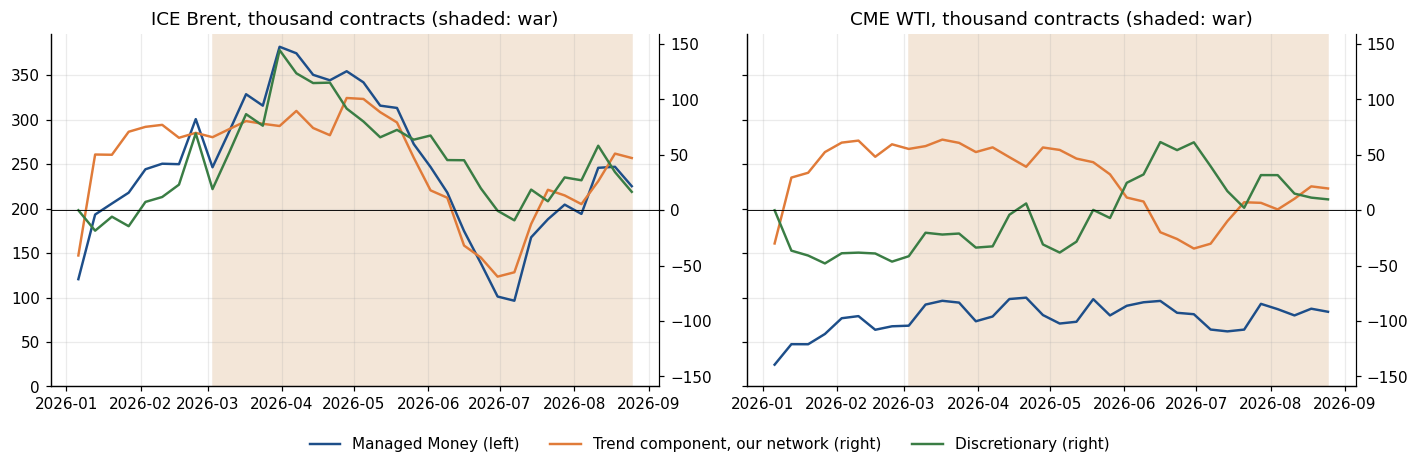

Trend component in 2026, thousand contracts (min to max): ICE Brent -60 to 101; CME WTI -35 to 64


In [5]:
crude = ['BRENT', 'WTI']
trend = wide('trend_position').loc['2026':, crude] / 1e3
position = mm.loc['2026':, crude] / 1e3
discretionary = (position - position.iloc[0]) - (trend - trend.iloc[0])
limit = 1.1 * pd.concat([trend, discretionary]).abs().max().max()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, market in zip(axes, crude):
    ax.axvspan(pd.Timestamp(WAR_START), position.index[-1], color=COLORS['war'], zorder=0)
    ax.plot(position.index, position[market], color=COLORS['mm'], lw=1.6, label='Managed Money (left)')
    right = ax.twinx()
    right.spines['right'].set_visible(True)
    right.plot(trend.index, trend[market], color=COLORS['trend'], lw=1.6, label='Trend component, our network (right)')
    right.plot(discretionary.index, discretionary[market], color=COLORS['disc'], lw=1.6, label='Discretionary (right)')
    right.axhline(0, color='black', lw=.6)
    right.set_ylim(-limit, limit)
    ax.set(title=f"{ct.NAMES[market]}, thousand contracts (shaded: war)", ylim=(0, None))
    ax.grid(alpha=.25)
handles = [h for a in (axes[0], right) for h in a.get_legend_handles_labels()[0]]
fig.legend(handles=handles, ncol=3, loc='lower center', bbox_to_anchor=(.5, -.02), frameon=False)
fig.tight_layout(rect=(0, .06, 1, 1))
fig.savefig(OUTPUT / 'figure3_our_network.png', dpi=160)
plt.show()
print('Trend component in 2026, thousand contracts (min to max): '
      + '; '.join(f'{ct.NAMES[m]} {trend[m].min():.0f} to {trend[m].max():.0f}' for m in crude))

**Observed.**

- $R^2$, May–Aug 2026: Brent 71.4%, natural gas 45.2%, heating oil 6.9%, WTI −82.9%, RBOB −114.4%, gasoil −264.7%.
- $R^2$, Mar–Apr 2026: Brent 7.6%, natural gas 32.6%, gasoil −4.6%, RBOB −90.3%, WTI −102.2%, heating oil −117.1%.
- $R^2$, Sep 2025–Feb 2026 against 2015–2025: Brent 68.8% vs 49.9%, WTI 17.0% vs 42.4%.
- $\rho$(trend flow, $\Delta MM$), May–Aug 2026: Brent 0.85, WTI 0.14.
- Trend position in 2026, thousand contracts: Brent −60 to 101, WTI −35 to 64.

## 3. Positions implied by the SG Trend replication

The replication ([`Replicating_CTA.ipynb`](Replicating_CTA.ipynb), Kestner 2020) holds, per dollar of capital,

$$w_{i,t}=k\cdot\frac13\sum_{L\in\{16,32,52\}}k_L\,\frac{s_{i,t}(L)}{N\,\sigma^{\text{ann}}_{i,t}},\qquad s_{i,t}(L)=\text{clip}\Big(\frac{\bar r_{i,t}(L)}{\sigma_{i,t}}\sqrt L,\,-1,\,1\Big),$$

with $N=16$, 90-day volatility, and $k_L$, $k$ fitted to SG Trend's volatility over 2007–2019. Among energy futures only WTI is one of the 16; the other markets use the same rule and leverages. With \$300bn of capital, $P_{m,t}=w_{m,t}\cdot\$300\text{bn}/(\text{price}\times\text{contract size})$. For each market,

$$\Delta MM_{m,t}=a_m+b_m\,\Delta P_{m,t}+e_{m,t}.$$

In [6]:
sg_tue = K.weekly_level_returns(K.load_sg_trend(PAPER_DATA / 'sg_cta_indices.csv'), TUE)
weekly16, vol16 = K.weekly_returns(daily16, TUE), K.weekly_vol(daily16, 90, TUE)
scales, k, counts = ct.ensemble_scales(weekly16, vol16, sg_tue)
_, weights16 = K.ensemble(weekly16, {90: vol16}, sg_tue)
vol = K.weekly_vol(returns, 90, TUE)
weights = ct.implied_weights(weekly, vol, scales, k, counts)
contracts = weights * K.AUM_USD / (prices.resample(TUE).last() * point_value)
d_pos = contracts.reindex(mm.index).diff()
capped = ct.capped(weekly, vol).reindex(mm.index)

gap = (weights['WTI'] - weights16['CL']).abs().max()
assert gap < 1e-12, gap
replication = K.portfolio(weekly16, weights16)
print(f"WTI's implied position equals the replication's own CL position (largest gap {gap:.0e}). "
      f"The replication still explains SG Trend: R² {K.r2(replication, sg_tue, K.OOS_WINDOW):.2f} over 2020–2026, "
      f"{K.r2(replication, sg_tue, ('2026', '2026')):.2f} in 2026.")

WTI's implied position equals the replication's own CL position (largest gap 3e-17). The replication still explains SG Trend: R² 0.66 over 2020–2026, 0.54 in 2026.


### Energy futures

When all three signals sit at $|s|=1$, $\Delta P$ depends only on volatility and price.

In [7]:
energy = ct.link(d_pos[ct.ENERGY], d_mm[ct.ENERGY], PERIODS)
energy['corr [95% CI]'] = [f'{r:.2f} [{lo:.2f}, {hi:.2f}]' for r, lo, hi in energy[['corr', 'low', 'high']].to_numpy()]
print('Correlation of the weekly MM change with the change in the SG-implied position [95% interval]')
display(by_period(energy, 'corr [95% CI]'))
print('Slope: MM contracts per contract of SG-implied flow')
display(by_period(energy, 'slope').round(2))
print('Share of weeks with all three signals at the cap')
display(pd.DataFrame({p: capped.loc[a:b, ct.ENERGY].mean() for p, (a, b) in PERIODS.items()})
        .rename(index=ct.NAMES).round(2))

crude_link = ct.link((d_pos['BRENT'] + d_pos['WTI']).to_frame('Brent + WTI'),
                     (d_mm['BRENT'] + d_mm['WTI']).to_frame('Brent + WTI'), PERIODS)
print('Brent and WTI together: MM change of both on the implied flow of both')
display(crude_link.set_index('period')[['corr', 'slope']].T.round(2))
for label in ['Sep 2025–Feb 2026', 'May–Aug 2026']:
    a, b = PERIODS[label]
    est, lo, hi = ct.bootstrap_gap(d_pos.loc[a:b], d_mm.loc[a:b], 'BRENT', 'WTI')
    print(f'{label}: Brent minus WTI correlation {est:.2f}, 95% bootstrap interval {lo:.2f} to {hi:.2f}')
for start in ['2026-04-01', '2026-05-01', '2026-06-01']:
    later = slice(start, END)
    print(f"From {start} ({len(d_mm.loc[later])} weeks): "
          + ', '.join(f'{ct.NAMES[m]} {d_pos.loc[later, m].corr(d_mm.loc[later, m]):.2f}' for m in OIL))

Correlation of the weekly MM change with the change in the SG-implied position [95% interval]


period,2015–2019,2020–2024,2025,Sep 2025–Feb 2026,Mar–Apr 2026,May–Aug 2026
market,,,,,,
ICE Brent,"0.49 [0.39, 0.57]","0.57 [0.48, 0.64]","0.66 [0.47, 0.79]","0.76 [0.53, 0.89]","-0.65 [-0.92, 0.03]","0.58 [0.14, 0.83]"
CME WTI,"0.57 [0.48, 0.64]","0.51 [0.42, 0.60]","0.52 [0.29, 0.69]","0.62 [0.31, 0.81]","-0.33 [-0.82, 0.43]","-0.23 [-0.64, 0.28]"
ICE Gasoil,"0.55 [0.46, 0.63]","0.53 [0.44, 0.61]","0.59 [0.38, 0.74]","0.68 [0.39, 0.84]","0.57 [-0.15, 0.90]","-0.06 [-0.52, 0.43]"
CME Heating oil,"0.49 [0.39, 0.57]","0.47 [0.37, 0.56]","0.28 [0.01, 0.52]","0.54 [0.19, 0.77]","-0.35 [-0.82, 0.41]","0.16 [-0.34, 0.60]"
CME RBOB gasoline,"0.53 [0.44, 0.61]","0.39 [0.28, 0.49]","0.62 [0.42, 0.77]","0.70 [0.42, 0.85]","-0.12 [-0.73, 0.59]","0.01 [-0.47, 0.49]"
CME Natural gas,"0.48 [0.38, 0.57]","0.51 [0.42, 0.60]","0.58 [0.36, 0.74]","0.66 [0.36, 0.83]","0.47 [-0.28, 0.86]","0.38 [-0.12, 0.73]"


Slope: MM contracts per contract of SG-implied flow


period,2015–2019,2020–2024,2025,Sep 2025–Feb 2026,Mar–Apr 2026,May–Aug 2026
market,,,,,,
ICE Brent,0.19,0.26,0.30,0.44,-0.57,1.23
CME WTI,0.24,0.19,0.14,0.15,-0.08,-0.18
ICE Gasoil,0.09,0.11,0.11,0.21,0.32,-0.04
CME Heating oil,0.05,0.06,0.04,0.12,-0.04,0.07
CME RBOB gasoline,0.07,0.06,0.08,0.10,-0.01,0.00
CME Natural gas,0.09,0.11,0.15,0.18,0.29,0.09


Share of weeks with all three signals at the cap


,2015–2019,2020–2024,2025,Sep 2025–Feb 2026,Mar–Apr 2026,May–Aug 2026
ICE Brent,0.15,0.16,0.00,0.00,0.89,0.29
CME WTI,0.10,0.15,0.00,0.00,0.44,0.12
ICE Gasoil,0.15,0.20,0.02,0.04,1.00,0.35
CME Heating oil,0.08,0.20,0.00,0.00,1.00,0.35
CME RBOB gasoline,0.04,0.18,0.00,0.00,0.78,0.41
CME Natural gas,0.07,0.07,0.00,0.00,0.00,0.00


Brent and WTI together: MM change of both on the implied flow of both


period,2015–2019,2020–2024,2025,Sep 2025–Feb 2026,Mar–Apr 2026,May–Aug 2026
corr,0.56,0.62,0.73,0.79,-0.83,0.47
slope,0.21,0.22,0.22,0.30,-0.31,0.55


Sep 2025–Feb 2026: Brent minus WTI correlation 0.14, 95% bootstrap interval -0.07 to 0.37


May–Aug 2026: Brent minus WTI correlation 0.81, 95% bootstrap interval 0.07 to 1.18
From 2026-04-01 (21 weeks): ICE Brent 0.53, CME WTI -0.22, ICE Gasoil -0.16, CME Heating oil 0.22, CME RBOB gasoline 0.01
From 2026-05-01 (17 weeks): ICE Brent 0.58, CME WTI -0.23, ICE Gasoil -0.06, CME Heating oil 0.16, CME RBOB gasoline 0.01
From 2026-06-01 (13 weeks): ICE Brent 0.70, CME WTI -0.24, ICE Gasoil 0.01, CME Heating oil 0.26, CME RBOB gasoline -0.12


The same correlation with MM in futures and delta-adjusted options combined:

In [8]:
with_options = pd.read_csv(PAPER_DATA / 'managed_money.csv', parse_dates=['report_week_tuesday'])
with_options = (with_options[with_options['basis'] == 'combined']
                .pivot(index='report_week_tuesday', columns='market', values='mm_net')[ct.ENERGY].loc[:END].diff())
display(by_period(ct.link(d_pos[ct.ENERGY], with_options, PERIODS), 'corr').round(2))
late = slice(*PERIODS['May–Aug 2026'])
print('Correlation of futures-only with futures-and-options MM changes, May–Aug 2026: '
      + ', '.join(f'{ct.NAMES[m]} {d_mm.loc[late, m].corr(with_options.loc[late, m]):.2f}' for m in ct.ENERGY))

period,2015–2019,2020–2024,2025,Sep 2025–Feb 2026,Mar–Apr 2026,May–Aug 2026
market,,,,,,
ICE Brent,0.49,0.55,0.68,0.78,-0.75,0.60
CME WTI,0.53,0.50,0.41,0.57,-0.27,0.11
ICE Gasoil,0.54,0.53,0.59,0.68,0.46,0.04
CME Heating oil,0.50,0.47,0.25,0.54,-0.27,0.17
CME RBOB gasoline,0.54,0.39,0.63,0.71,-0.12,-0.01
CME Natural gas,0.48,0.51,0.58,0.66,0.47,0.38


Correlation of futures-only with futures-and-options MM changes, May–Aug 2026: ICE Brent 0.95, CME WTI 0.84, ICE Gasoil 0.96, CME Heating oil 1.00, CME RBOB gasoline 1.00, CME Natural gas 1.00


13-week rolling $\rho(\Delta MM,\Delta P)$, and $b_m$ by calendar year.

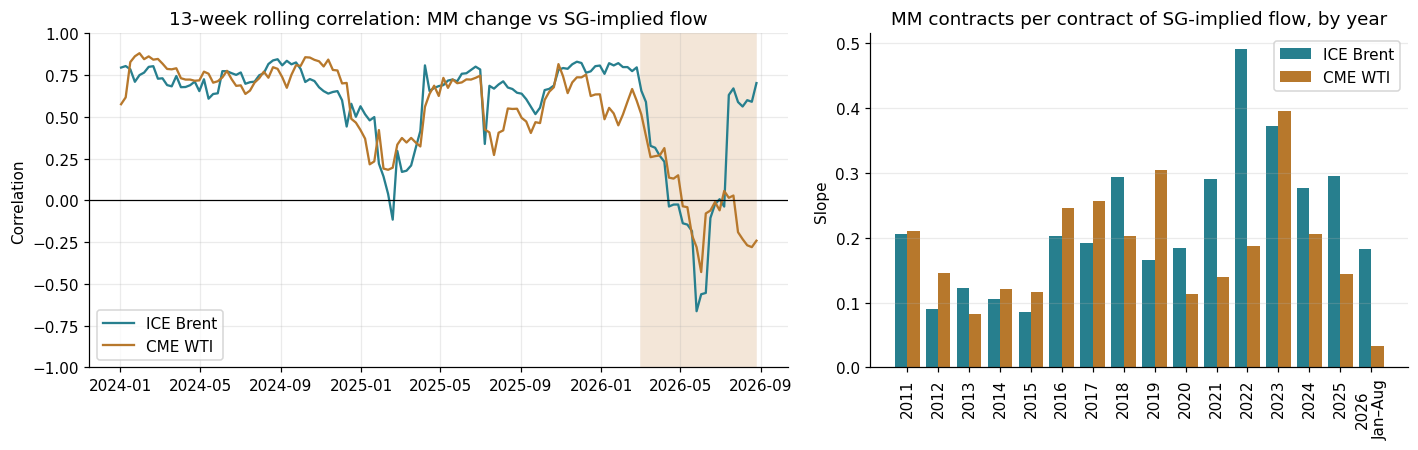

Brent share of the crude slope, by year: 2011 50%, 2012 38%, 2013 60%, 2014 46%, 2015 42%, 2016 45%, 2017 43%, 2018 59%, 2019 35%, 2020 62%, 2021 68%, 2022 72%, 2023 48%, 2024 57%, 2025 67%, 2026 84%


In [9]:
rolling = d_pos[crude].rolling(13).corr(d_mm[crude]).loc['2024':END]
yearly_slope = ct.link(d_pos[crude], d_mm[crude], {str(y): (str(y), str(y)) for y in range(2011, 2027)}) \
    .pivot(index='period', columns='market', values='slope')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1.3, 1]})
ax1.axvspan(pd.Timestamp(WAR_START), pd.Timestamp(END), color=COLORS['war'], zorder=0)
for market in crude:
    ax1.plot(rolling.index, rolling[market], color=COLORS[market], lw=1.5, label=ct.NAMES[market])
ax1.axhline(0, color='black', lw=.8)
ax1.set(title='13-week rolling correlation: MM change vs SG-implied flow', ylim=(-1, 1), ylabel='Correlation')
ax1.grid(alpha=.25)
ax1.legend(loc='lower left')
x = np.arange(len(yearly_slope))
for offset, market in [(-.2, 'BRENT'), (.2, 'WTI')]:
    ax2.bar(x + offset, yearly_slope[market], .4, color=COLORS[market], label=ct.NAMES[market])
ax2.set_xticks(x, [y if y != '2026' else '2026\nJan–Aug' for y in yearly_slope.index], rotation=90)
ax2.set(title='MM contracts per contract of SG-implied flow, by year', ylabel='Slope')
ax2.grid(axis='y', alpha=.25)
ax2.legend()
fig.tight_layout()
fig.savefig(OUTPUT / 'brent_wti_link.png', dpi=160)
plt.show()
share = yearly_slope['BRENT'] / yearly_slope.sum(axis=1)
print('Brent share of the crude slope, by year: ' + ', '.join(f'{y} {s:.0%}' for y, s in share.items()))

**Observed.** Replication against SG Trend: $R^2$ = 0.66 over 2020–2026, 0.54 in 2026.

| | Sep 2025–Feb 2026 | Mar–Apr 2026 | May–Aug 2026 |
|---|---|---|---|
| $\rho$, Brent [95%] | 0.76 [0.53, 0.89] | −0.65 [−0.92, 0.03] | 0.58 [0.14, 0.83] |
| $\rho$, WTI [95%] | 0.62 [0.31, 0.81] | −0.33 [−0.82, 0.43] | −0.23 [−0.64, 0.28] |
| $b$, Brent | 0.44 | −0.57 | 1.23 |
| $b$, WTI | 0.15 | −0.08 | −0.18 |
| All signals capped, Brent | 0% | 89% | 29% |
| All signals capped, WTI | 0% | 44% | 12% |

- Later window, Brent vs WTI: from April 0.53, −0.22; from May 0.58, −0.23; from June 0.70, −0.24.
- Brent and WTI pooled, May–Aug 2026: $\rho$ = 0.47, $b$ = 0.55. Earlier periods: $b$ = 0.21–0.30.
- May–Aug 2026, other markets: gasoil −0.06, heating oil 0.16, RBOB 0.01, natural gas 0.38.
- With options, May–Aug 2026: WTI 0.11, Brent 0.60. $\mathrm{corr}(\Delta MM^{\text{fut}},\Delta MM^{\text{fut+opt}})$: WTI 0.84, others 0.95–1.00.

## 4. All 18 markets

$\rho(\Delta MM,\Delta P)$ by year, and 2025 and 2026 against 2015–2024, with a Fisher test $H_0:\rho_{\text{period}}=\rho_{2015-2024}$ and the share of capped weeks.

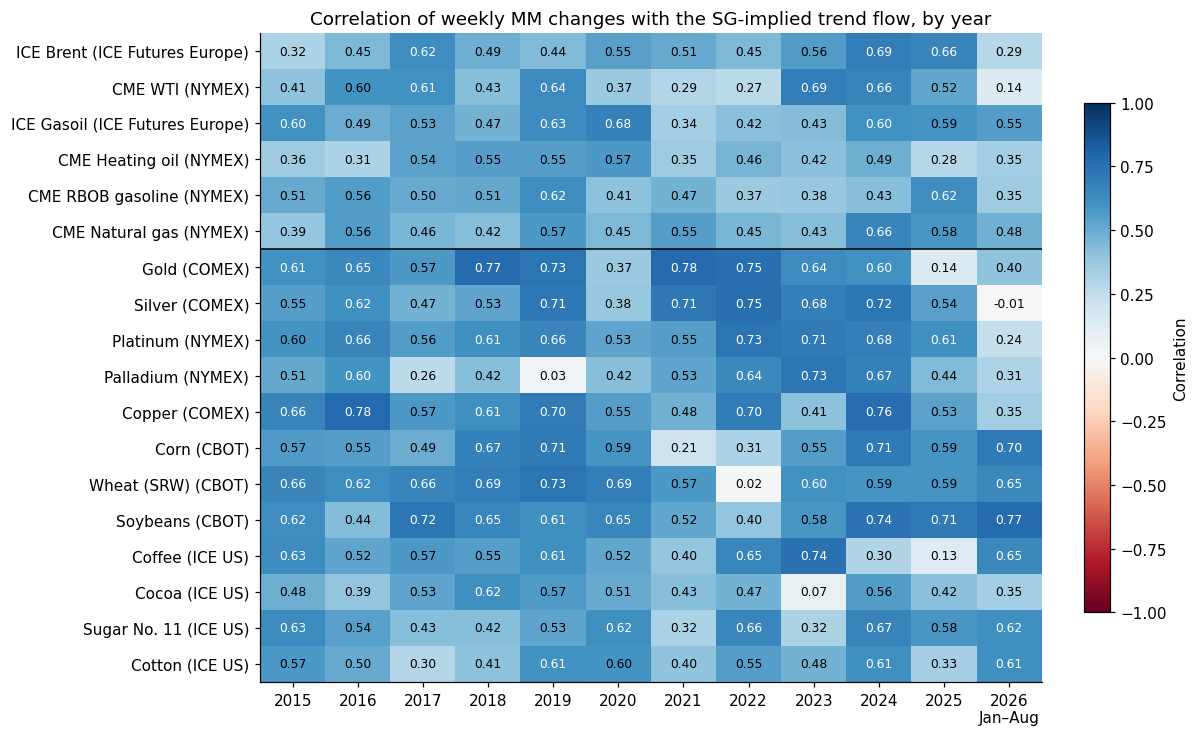

period,exchange,2015–2024,2025,2026 Jan–Aug,May–Aug 2026,"p, 2025 vs 2015–2024","p, 2026 Jan–Aug vs 2015–2024","capped, 2025","capped, 2026 Jan–Aug","capped, May–Aug 2026"
market,,,,,,,,,,
ICE Brent,ICE Futures Europe,0.53,0.66,0.29,0.58,0.16,0.11,0.00,0.38,0.29
CME WTI,NYMEX,0.54,0.52,0.14,-0.23,0.83,0.01,0.00,0.18,0.12
ICE Gasoil,ICE Futures Europe,0.54,0.59,0.55,-0.06,0.62,0.90,0.02,0.44,0.35
CME Heating oil,NYMEX,0.48,0.28,0.35,0.16,0.12,0.38,0.00,0.44,0.35
CME RBOB gasoline,NYMEX,0.47,0.62,0.35,0.01,0.15,0.43,0.00,0.41,0.41
CME Natural gas,NYMEX,0.49,0.58,0.48,0.38,0.41,0.95,0.00,0.00,0.00
Gold,COMEX,0.65,0.14,0.40,0.17,0.00,0.06,0.65,0.29,0.00
Silver,COMEX,0.57,0.54,-0.01,-0.08,0.76,0.00,0.35,0.26,0.00
Platinum,NYMEX,0.61,0.61,0.24,0.33,0.97,0.01,0.25,0.12,0.00


Average correlation, 12 non-energy US commodities: 2015–2024 0.56, 2025 0.47, 2026 Jan–Aug 0.47, May–Aug 2026 0.47


In [10]:
years = range(2015, 2027)
yearly_corr = ct.link(d_pos, d_mm, {str(y): (str(y), str(y)) for y in years}) \
    .pivot(index='market', columns='period', values='corr').loc[ct.ENERGY + ct.OTHER]

fig, ax = plt.subplots(figsize=(11, 6.8))
image = ax.imshow(yearly_corr, cmap='RdBu', vmin=-1, vmax=1, aspect='auto')
for (i, j), value in np.ndenumerate(yearly_corr.to_numpy()):
    ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=8,
            color='white' if abs(value) > .6 else 'black')
ax.set_xticks(range(len(years)), [str(y) if y < 2026 else '2026\nJan–Aug' for y in years])
ax.set_yticks(range(len(yearly_corr)), [f'{ct.NAMES[m]} ({ct.EXCHANGE[m]})' for m in yearly_corr.index])
ax.axhline(len(ct.ENERGY) - .5, color='black', lw=1)
ax.set_title('Correlation of weekly MM changes with the SG-implied trend flow, by year')
fig.colorbar(image, ax=ax, fraction=.03, label='Correlation')
fig.tight_layout()
fig.savefig(OUTPUT / 'commodity_link_heatmap.png', dpi=160)
plt.show()

windows = {'2015–2024': ('2015', '2024'), '2025': ('2025', '2025'), '2026 Jan–Aug': ('2026', END),
           'May–Aug 2026': PERIODS['May–Aug 2026']}
links = ct.link(d_pos, d_mm, windows).pivot(index='market', columns='period')
summary = links['corr'][list(windows)].copy()
for label in ['2025', '2026 Jan–Aug']:
    summary[f'p, {label} vs 2015–2024'] = ct.fisher_p(links['corr'][label], links['weeks'][label],
                                                      links['corr']['2015–2024'], links['weeks']['2015–2024'])
for label in ['2025', '2026 Jan–Aug', 'May–Aug 2026']:
    a, b = windows[label]
    summary[f'capped, {label}'] = capped.loc[a:b].mean()
summary = summary.loc[ct.ENERGY + ct.OTHER]
summary.insert(0, 'exchange', pd.Series(ct.EXCHANGE))
display(summary.rename(index=ct.NAMES).round(2))
others = summary.loc[ct.OTHER, list(windows)].mean()
print('Average correlation, 12 non-energy US commodities: ' + ', '.join(f'{p} {v:.2f}' for p, v in others.items()))

**Observed.** $\rho$, 2026 Jan–Aug against 2015–2024, with Fisher $p$.

- Metals: silver −0.01 vs 0.57 ($p<0.01$), platinum 0.24 vs 0.61 (0.01), gold 0.40 vs 0.65 (0.06), copper 0.35 vs 0.61 (0.06), palladium 0.31 vs 0.48 (0.26).
- Grains: corn 0.70 vs 0.57, wheat 0.65 vs 0.64, soybeans 0.77 vs 0.59.
- Softs: coffee 0.65 vs 0.56, sugar 0.62 vs 0.52, cotton 0.61 vs 0.50, cocoa 0.35 vs 0.44 ($p$ = 0.54).
- Natural gas: 0.48 vs 0.49. WTI: 0.14 vs 0.54 ($p$ = 0.01). Brent: 0.29 vs 0.53 (0.11).
- 12-market average: 0.56 in 2015–2024, 0.47 in 2025, 0.47 in 2026.
- Gold 2025: $\rho$ = 0.14 ($p<0.01$), capped 65% of weeks. May–Aug 2026, capped 0%: gold 0.17, silver −0.08.
- May–Aug 2026, ICE markets: Brent 0.58, gasoil −0.06.

## Not yet run

1. Network with the comment's one-year window.
2. London cocoa, Robusta coffee, white sugar and LME copper positions.
3. Data after 2026-08-25: the CFTC file runs to 2026-10-13; energy COT and Brent, gasoil, heating oil and RBOB prices stop earlier.

## Save results

In [11]:
pd.concat({'mm_change': d_mm, 'sg_implied_change': d_pos}, axis=1).loc['2009':END].to_csv(OUTPUT / 'weekly_changes.csv')
contracts.loc['2009':END].to_csv(OUTPUT / 'sg_implied_contracts.csv')
nn.to_csv(OUTPUT / 'nn_decomposition_2015_2026.csv', index=False)
nn_r2.to_csv(OUTPUT / 'nn_r2_by_period.csv')
price_link.to_csv(OUTPUT / 'price_link_by_period.csv', index=False)
energy.to_csv(OUTPUT / 'energy_link_by_period.csv', index=False)
yearly_corr.to_csv(OUTPUT / 'commodity_link_by_year.csv')
summary.to_csv(OUTPUT / 'commodity_link_summary.csv')

## References

- Sun, W-Y., Bouchouev, I. and Fattouh, B. (2026), *Shifting Oil Market Positioning During the Strait of Hormuz Crisis*, OIES Energy Comment, October (`references/`). Figure 3 and its footnote 7 on the model.
- Sun, W-Y., Bouchouev, I. and Fattouh, B. (2026), [Momentum Trading and Managed Money Positioning in Energy](https://www.oxfordenergy.org/wpcms/wp-content/uploads/2026/03/Insight-177-Money-Positioning-in-Energy.pdf), OIES Insight 177.
- Kestner, L. N. (2020), *Replicating CTA Positioning: An Improved Method*, [SSRN 3674828](https://ssrn.com/abstract=3674828), as replicated in [`Replicating_CTA.ipynb`](Replicating_CTA.ipynb).
- CFTC, [Disaggregated Commitments of Traders, futures only](https://publicreporting.cftc.gov/) (dataset `72hh-3qpy`), and [explanatory notes](https://www.cftc.gov/MarketReports/CommitmentsofTraders/DisaggregatedExplanatoryNotes/index.htm) on the Managed Money category.
- ICE Futures Europe, Commitments of Traders for Brent and gasoil (via Bloomberg).